In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from numba import njit

# Parâmetros exatos de Onsager (J = kB = 1)
Tc_exact = 2 / np.log(1 + np.sqrt(2)) 

@njit
def inicializar_rede(L):
    """Gera uma rede L x L com spins aleatórios +1 ou -1."""
    # Numba prefere limites explícitos no randint (low=0, high=2)
    return 2 * np.random.randint(0, 2, size=(L, L)) - 1

@njit
def passo_metropolis(rede, beta):
    """
    Executa um passo de Monte Carlo (L^2 tentativas de flip) via Metropolis.
    Condições Periódicas de Contorno são aplicadas usando módulo (%).
    """
    L = rede.shape[0]
    tentativas = L * L
    aceitacoes = 0
    
    for _ in range(tentativas):
        i = np.random.randint(0, L)
        j = np.random.randint(0, L)
        spin = rede[i, j]
        
        # Soma dos primeiros vizinhos com PBC
        vizinhos = rede[(i+1)%L, j] + rede[(i-1)%L, j] + \
                   rede[i, (j+1)%L] + rede[i, (j-1)%L]
        
        # Variação de energia ao inverter o spin (J = 1)
        dE = 2 * spin * vizinhos
        
        # Critério de Aceitação de Metropolis
        if dE <= 0 or np.random.rand() < np.exp(-dE * beta):
            rede[i, j] *= -1
            aceitacoes += 1
            
    return rede, aceitacoes

@njit
def calcular_energia_magnetizacao(rede):
    """Calcula a energia total e a magnetização total da rede."""
    L = rede.shape[0]
    energia = 0.0
    magnetizacao = np.sum(rede)
    
    for i in range(L):
        for j in range(L):
            spin = rede[i, j]
            # Para evitar contagem dupla na energia, olhamos apenas para baixo e direita
            vizinhos = rede[(i+1)%L, j] + rede[i, (j+1)%L]
            energia -= spin * vizinhos
            
    return energia, magnetizacao

In [2]:
@njit
def simular_ising(L, temperaturas, passos_term, passos_medida):
    """
    Simula o modelo de Ising para um vetor de temperaturas e retorna as grandezas termodinâmicas.
    """
    num_T = len(temperaturas)
    
    # Arrays para armazenar os resultados
    E_med = np.zeros(num_T)
    M_med = np.zeros(num_T)
    C_v = np.zeros(num_T)
    Chi = np.zeros(num_T)
    Binder = np.zeros(num_T)
    
    N = L * L # Número total de spins
    
    for idx_T in range(num_T):
        T = temperaturas[idx_T]
        beta = 1.0 / T
        rede = inicializar_rede(L)
        
        # Termalização (atingir o equilíbrio)
        for _ in range(passos_term):
            passo_metropolis(rede, beta)
            
        # Medidas
        E_soma = E2_soma = M_soma = M2_soma = M4_soma = 0.0
        
        for _ in range(passos_medida):
            passo_metropolis(rede, beta)
            E, M = calcular_energia_magnetizacao(rede)
            
            E_soma += E
            E2_soma += E**2
            M_abs = abs(M)
            M_soma += M_abs
            M2_soma += M**2
            M4_soma += M**4
            
        # Médias termodinâmicas (por spin)
        e_mean = E_soma / passos_medida
        e2_mean = E2_soma / passos_medida
        m_mean = M_soma / passos_medida
        m2_mean = M2_soma / passos_medida
        m4_mean = M4_soma / passos_medida
        
        E_med[idx_T] = e_mean / N
        M_med[idx_T] = m_mean / N
        C_v[idx_T] = (beta**2 / N) * (e2_mean - e_mean**2)
        Chi[idx_T] = (beta / N) * (m2_mean - m_mean**2)
        
        # Cumulante de Binder (U4)
        if m2_mean != 0:
            Binder[idx_T] = 1.0 - (m4_mean / (3.0 * (m2_mean**2)))
        else:
            Binder[idx_T] = 0.0
            
    return E_med, M_med, C_v, Chi, Binder

In [3]:
# Configurações da Simulação
tamanhos_L = [8, 16, 32] # Redes de diferentes tamanhos
temperaturas = np.linspace(1.5, 3.2, 40) # Varredura de T
passos_term = 2000
passos_medida = 4000

resultados = {}

print("Iniciando simulações...")
for L in tamanhos_L:
    print(f"Simulando rede L={L}...")
    E, M, Cv, Chi, U4 = simular_ising(L, temperaturas, passos_term, passos_medida)
    resultados[L] = {'E': E, 'M': M, 'Cv': Cv, 'Chi': Chi, 'U4': U4}
print("Simulações concluídas!")

Iniciando simulações...
Simulando rede L=8...
Simulando rede L=16...
Simulando rede L=32...
Simulações concluídas!


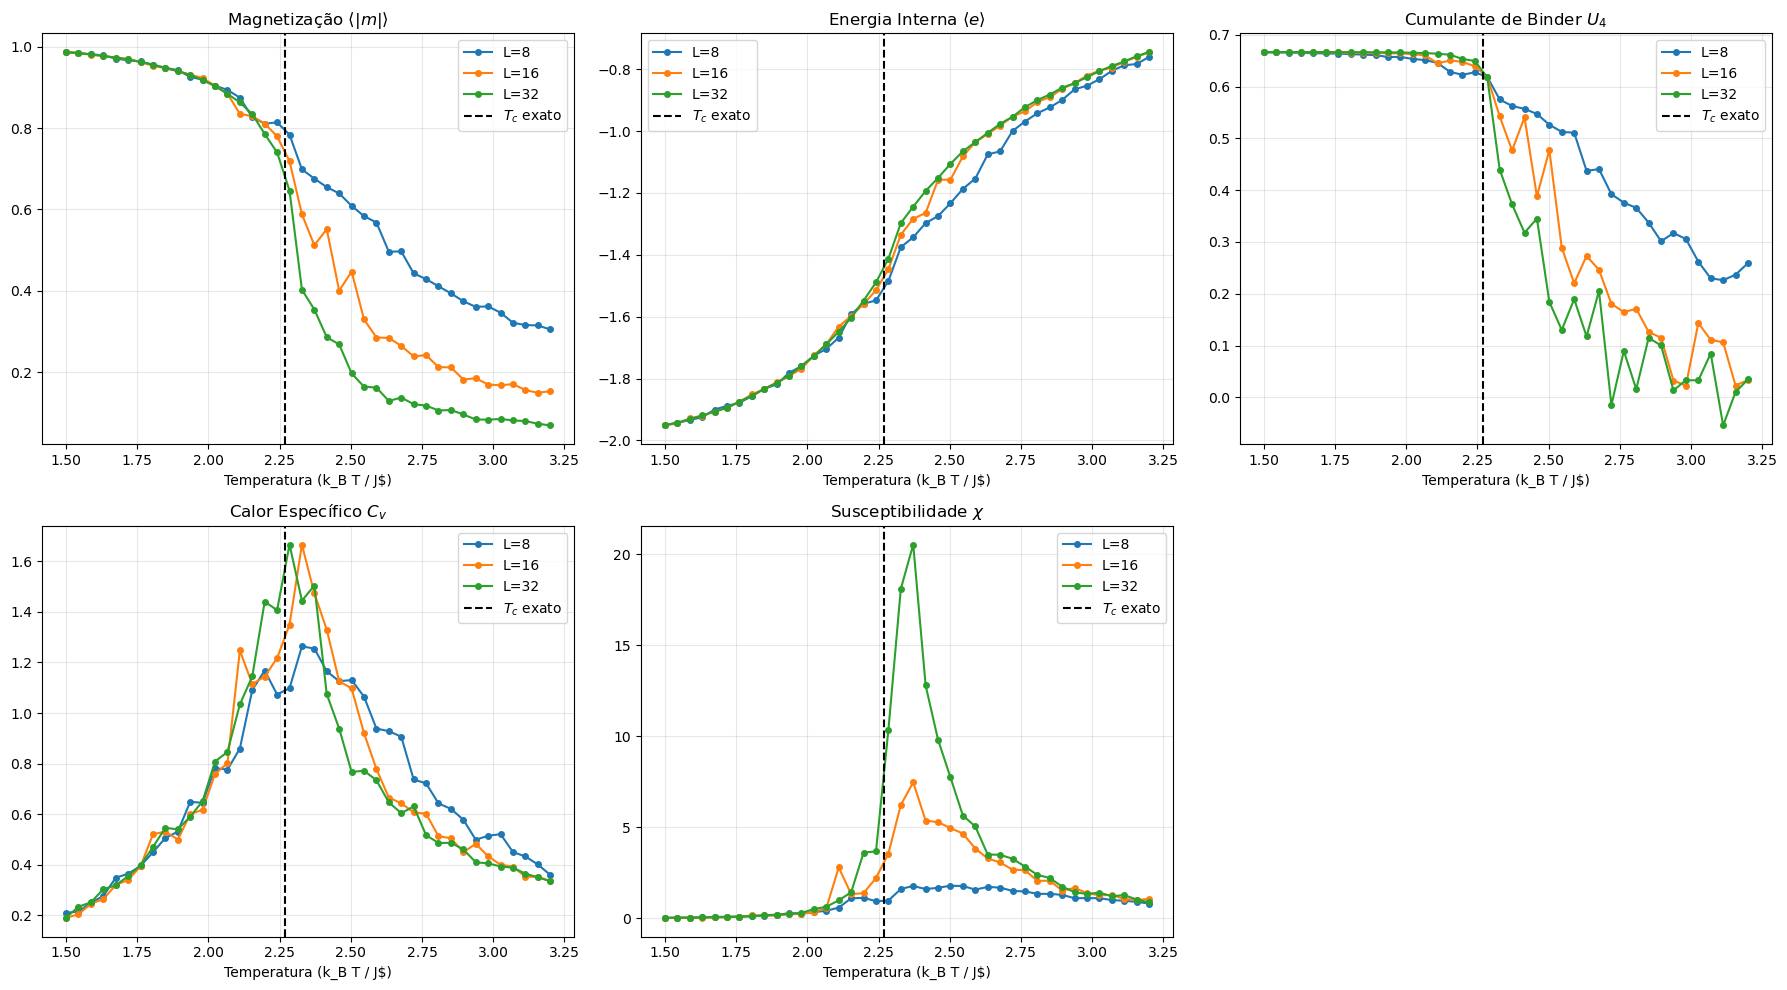

In [15]:
fig, axs = plt.subplots(2, 3, figsize=(18, 10))
cores = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', 'black']

for idx, L in enumerate(tamanhos_L):
    res = resultados[L]
    
    # Magnetização
    axs[0, 0].plot(temperaturas, res['M'], 'o-', color=cores[idx], label=f'L={L}', markersize=4)
    # Energia
    axs[0, 1].plot(temperaturas, res['E'], 'o-', color=cores[idx], label=f'L={L}', markersize=4)
    # Calor Específico
    axs[1, 0].plot(temperaturas, res['Cv'], 'o-', color=cores[idx], label=f'L={L}', markersize=4)
    # Susceptibilidade
    axs[1, 1].plot(temperaturas, res['Chi'], 'o-', color=cores[idx], label=f'L={L}', markersize=4)
    # Cumulante de Binder
    axs[0, 2].plot(temperaturas, res['U4'], 'o-', color=cores[idx], label=f'L={L}', markersize=4)

titulos = [
    (r'Magnetização $\langle |m| \rangle$', axs[0, 0]), 
    (r'Energia Interna $\langle e \rangle$', axs[0, 1]),
    (r'Calor Específico $C_v$', axs[1, 0]),
    (r'Susceptibilidade $\chi$', axs[1, 1]),
    (r'Cumulante de Binder $U_4$', axs[0, 2])
]

# Configurando eixos e adicionando linha da temperatura crítica (Tc)
for title, ax in titulos:
    ax.set_title(title)
    ax.set_xlabel('Temperatura (k_B T / J$)')
    ax.axvline(x=Tc_exact, color='k', linestyle='--', label='$T_c$ exato')
    ax.grid(True, alpha=0.3)
    ax.legend()

axs[1, 2].axis('off') # Esconder último plot não usado
plt.tight_layout()
plt.show()

GIF salvo com sucesso na pasta do projeto!


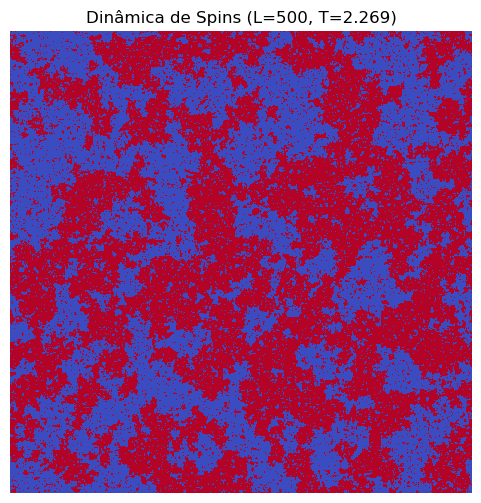

In [30]:
# Configuração para animação (Escolha T = 2.269 para ver a opalescência crítica)
L_anim = 500
T_anim = Tc_exact
beta_anim = 1.0 / T_anim
rede_anim = inicializar_rede(L_anim)

fig_anim, ax_anim = plt.subplots(figsize=(6, 6))
img = ax_anim.imshow(rede_anim, cmap='coolwarm', vmin=-1, vmax=1, interpolation='nearest')
ax_anim.set_title(f'Dinâmica de Spins (L={L_anim}, T={T_anim:.3f})')
ax_anim.axis('off')

# Termalização inicial rápida (opcional)
for _ in range(100):
    passo_metropolis(rede_anim, beta_anim)

def atualizar(frame):
    # A cada frame, avançamos alguns passos de Monte Carlo para a dinâmica ficar visível
    for _ in range(5): 
        passo_metropolis(rede_anim, beta_anim)
    img.set_array(rede_anim)
    return [img]

anim = animation.FuncAnimation(fig_anim, atualizar, frames=100, interval=50, blit=True)

anim.save('dinamica_ising.gif', writer='pillow', fps=15)

print("GIF salvo com sucesso na pasta do projeto!")

# No Jupyter Notebook, você pode exibir usando:
#HTML(anim.to_jshtml())
plt.show()

KeyboardInterrupt: 

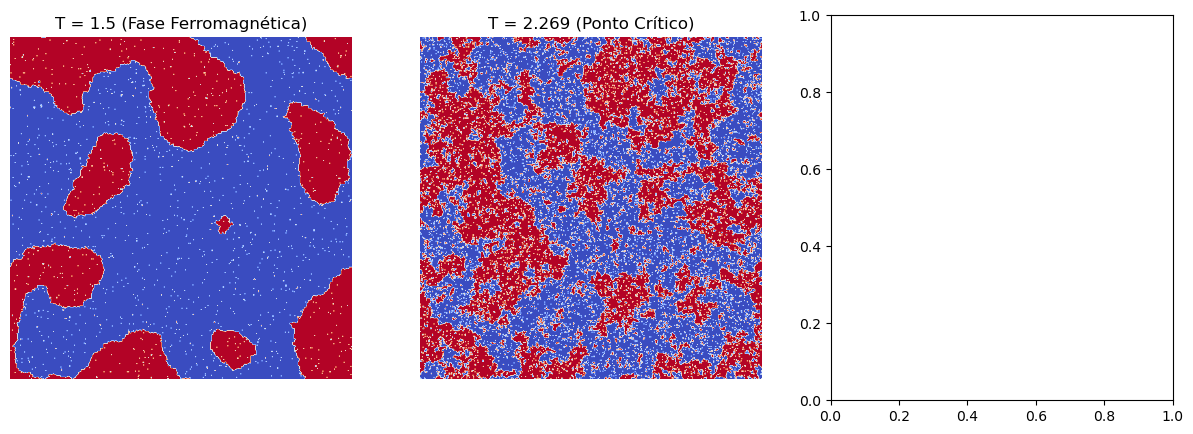

In [26]:
# CÉLULA: Comparação de configurações
L_snap = 500
temperaturas_snap = [1.5, Tc_exact, 3.5]
titulos_snap = ['T = 1.5 (Fase Ferromagnética)', 
                f'T = {Tc_exact:.3f} (Ponto Crítico)', 
                'T = 3.5 (Fase Paramagnética)']

fig, axs = plt.subplots(1, 3, figsize=(15, 5))

for i, T in enumerate(temperaturas_snap):
    beta = 1.0 / T
    rede = inicializar_rede(L_snap)
    
    # Termalização longa para garantir equilíbrio
    for _ in range(2000):
        passo_metropolis(rede, beta)
        
    axs[i].imshow(rede, cmap='coolwarm', vmin=-1, vmax=1)
    axs[i].set_title(titulos_snap[i], fontsize=12)
    axs[i].axis('off')

plt.tight_layout()
plt.show()

In [45]:

# CÉLULA: Comparação de configurações em múltiplas escalas

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

L_snap = 1000

temperaturas_snap = [1.5, Tc_exact, 3.5]

titulos_snap = ['Ferromagnética','Crítica', 'Paramagnética']


# Coordenadas do centro dos recortes
centro = L_snap // 2

# Gerar as configurações
configuracoes = []

for T in temperaturas_snap:
    beta = 1.0 / T
    rede = inicializar_rede(L_snap)

    print(f"Termalizando T = {T:.3f}...")

    for _ in range(2000):
        passo_metropolis(rede, beta)

    configuracoes.append(rede.copy())

Termalizando T = 1.500...
Termalizando T = 2.269...
Termalizando T = 3.500...


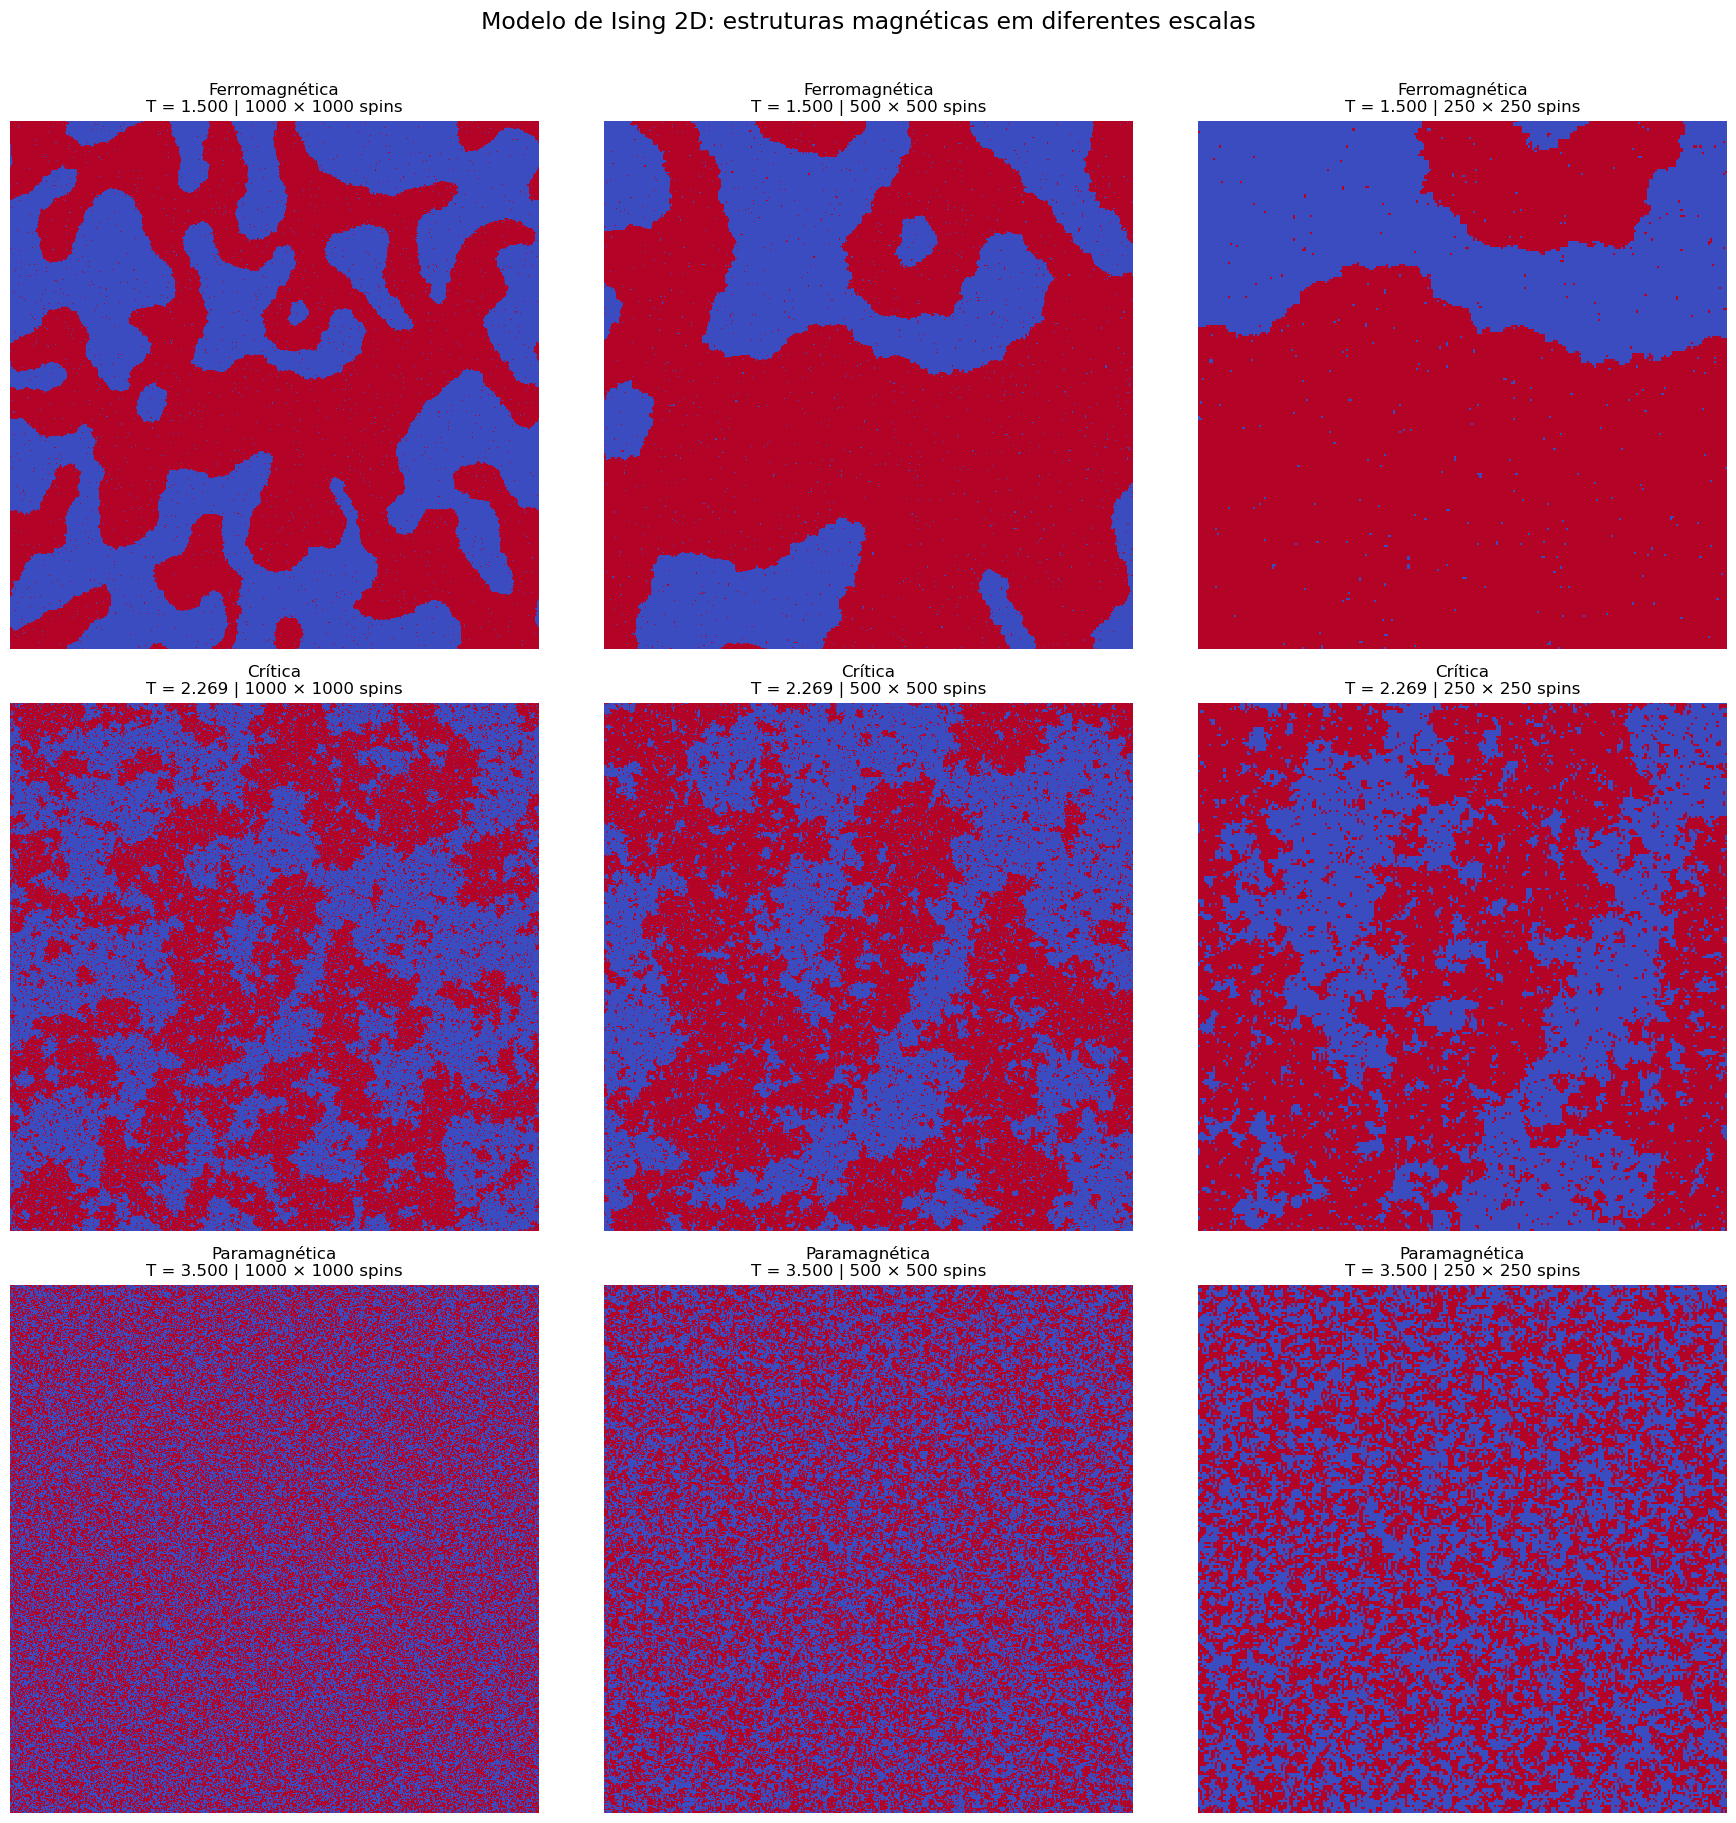

In [42]:
# Dimensões dos recortes: mesma região central da rede
escalas = [1000, 500, 250]

# Criar figura com 3 temperaturas e 3 escalas
fig, axs = plt.subplots(3, 3, figsize=(18, 18) )

for i, (T, rede) in enumerate(zip(temperaturas_snap, configuracoes)):
    for j, escala in enumerate(escalas):

        ax = axs[i, j]

        # Limites do recorte
        inicio = centro - escala // 2
        fim = inicio + escala

        # Recortar a configuração original
        recorte = rede[inicio:fim, inicio:fim]

        # Exibir sem interpolação suavizante
        ax.imshow(recorte, cmap='coolwarm', vmin=-1, vmax=1, interpolation='nearest', aspect='equal', resample=False)

        ax.set_title(
            f'{titulos_snap[i]}\n'
            f'T = {T:.3f} | {escala} × {escala} spins',
            fontsize=12
        )

        ax.axis('off')


axs[0, 0].set_ylabel(
    'T < Tc',
    fontsize=14,
    labelpad=15
)

axs[1, 0].set_ylabel(
    'T = Tc',
    fontsize=14,
    labelpad=15
)

axs[2, 0].set_ylabel(
    'T > Tc',
    fontsize=14,
    labelpad=15
)

fig.suptitle(
    'Modelo de Ising 2D: estruturas magnéticas em diferentes escalas',
    fontsize=17,
    y=1.01
)

plt.tight_layout()

# Exportação em alta resolução
plt.savefig(
    'ising_multiplas_escalas.png',
    dpi=400,
    bbox_inches='tight'
)

plt.show()


Simulando T = 1.5000
Simulando T = 2.2692
Simulando T = 3.5000


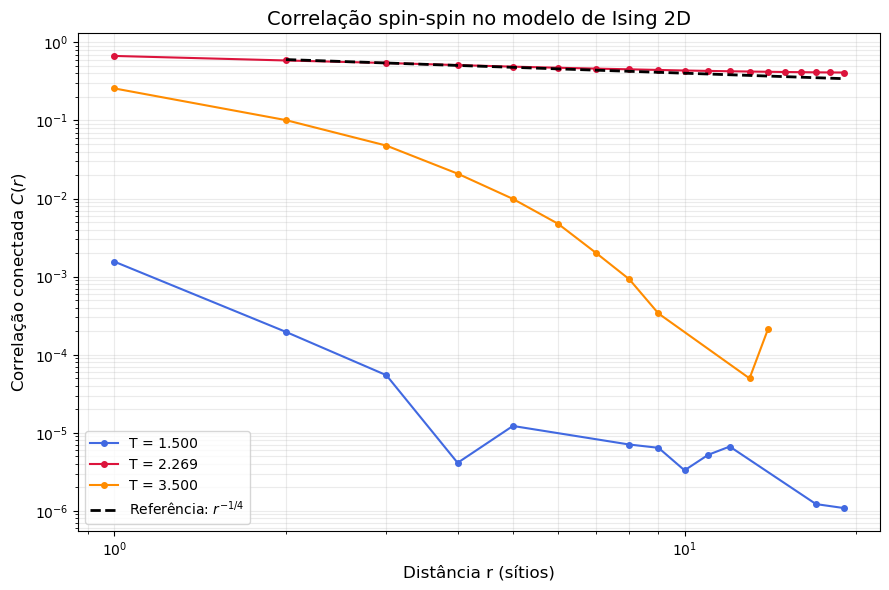

In [44]:
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Parâmetros da simulação
# --------------------------------------------------

L_corr = 100

temperaturas_corr = [
    1.5,
    Tc_exact,
    3.5
]

n_equilibrio = 3000
n_passos = 12000
intervalo_amostras = 20

# --------------------------------------------------
# 2. Cálculo da correlação espacial por FFT
# --------------------------------------------------

def mapa_correlacao(rede):
    """
    Calcula <s(i,j) s(i+dx,j+dy)> para todos os deslocamentos,
    usando condições periódicas de contorno.
    """

    transformada = np.fft.fft2(rede)

    correlacao = np.fft.ifft2(
        np.abs(transformada)**2
    ).real

    correlacao /= rede.size

    return np.fft.fftshift(correlacao)


# --------------------------------------------------
# 3. Correlação radial média C(r)
# --------------------------------------------------

def correlacao_radial(configuracoes):
    """
    Calcula a correlação conectada e faz a média radial.
    """

    L = configuracoes[0].shape[0]

    mapas = []

    magnetizacoes = []

    for rede in configuracoes:

        mapas.append(mapa_correlacao(rede))

        magnetizacoes.append(np.mean(rede))

    # Média dos mapas de correlação
    C_mapa = np.mean(mapas, axis=0)

    # Magnetização média do conjunto de configurações
    m_medio = np.mean(magnetizacoes)

    # Correlação conectada
    C_mapa -= m_medio**2

    # Coordenadas dos deslocamentos
    coordenadas = np.arange(-L//2, L//2)

    dx, dy = np.meshgrid(
        coordenadas,
        coordenadas,
        indexing='ij'
    )

    distancia = np.sqrt(dx**2 + dy**2)

    # Agrupamento por distância radial
    bins = np.rint(distancia).astype(int)

    soma = np.bincount(
        bins.ravel(),
        weights=C_mapa.ravel()
    )

    contagem = np.bincount(bins.ravel())

    C_r = soma / np.maximum(contagem, 1)

    r = np.arange(len(C_r))

    # Consideramos apenas distâncias menores que L/2
    limite = L // 2

    r = r[1:limite]
    C_r = C_r[1:limite]

    return r, C_r


# --------------------------------------------------
# 4. Simulação e coleta de configurações
# --------------------------------------------------

# --------------------------------------------------
# 1. Parâmetros da simulação
# --------------------------------------------------

L_corr = 40

temperaturas_corr = [
    1.5,
    Tc_exact,
    3.5
]

n_equilibrio_sweeps = 500
n_amostras = 300
intervalo_sweeps = 5


# --------------------------------------------------
# 2. Uma varredura completa da rede
# --------------------------------------------------

def monte_carlo_sweep(rede, beta):

    L = rede.shape[0]
    N = L * L

    for _ in range(N):
        passo_metropolis(rede, beta)


# --------------------------------------------------
# 3. Simulação e coleta de configurações
# --------------------------------------------------

resultados_corr = {}

for T in temperaturas_corr:

    print(f"Simulando T = {T:.4f}")

    beta = 1.0 / T

    rede = inicializar_rede(L_corr)

    # Equilíbrio térmico
    for _ in range(n_equilibrio_sweeps):
        monte_carlo_sweep(rede, beta)

    configuracoes = []

    # Amostragem das configurações
    for amostra in range(n_amostras):

        for _ in range(intervalo_sweeps):
            monte_carlo_sweep(rede, beta)

        configuracoes.append(rede.copy())

    r, C_r = correlacao_radial(configuracoes)

    resultados_corr[T] = (r, C_r)


# --------------------------------------------------
# 5. Gráfico em escala log-log
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 6))

cores = ['royalblue', 'crimson', 'darkorange']

for T, cor in zip(temperaturas_corr, cores):

    r, C_r = resultados_corr[T]

    # Apenas valores positivos podem ser representados
    # em escala logarítmica
    mascara = C_r > 0

    ax.loglog(
        r[mascara],
        C_r[mascara],
        'o-',
        markersize=4,
        linewidth=1.5,
        color=cor,
        label=f'T = {T:.3f}'
    )


# --------------------------------------------------
# 6. Reta de referência: C(r) ~ r^(-1/4)
# --------------------------------------------------

r_ref = np.arange(2, L_corr // 2)

# Usa a curva crítica para definir a amplitude da reta
r_crit, C_crit = resultados_corr[Tc_exact]

# Escolhe um ponto positivo da curva crítica como referência
validos = (r_crit >= 3) & (r_crit <= L_corr // 4) & (C_crit > 0)

if np.any(validos):

    indice = np.where(validos)[0][0]

    r0 = r_crit[indice]
    C0 = C_crit[indice]

    referencia = C0 * (r_ref / r0)**(-1/4)

    ax.loglog(
        r_ref,
        referencia,
        'k--',
        linewidth=2,
        label=r'Referência: $r^{-1/4}$'
    )


# --------------------------------------------------
# 7. Formatação
# --------------------------------------------------

ax.set_xlabel('Distância r (sítios)', fontsize=12)
ax.set_ylabel(r'Correlação conectada $C(r)$', fontsize=12)

ax.set_title(
    'Correlação spin-spin no modelo de Ising 2D',
    fontsize=14
)

ax.grid(True, which='both', alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()

In [46]:
magnetizacao = []

for _ in range(n_equilibrio_sweeps):

    monte_carlo_sweep(rede, beta)

    magnetizacao.append(np.mean(rede))

plt.figure(figsize=(9, 4))

plt.plot(magnetizacao)

plt.xlabel('Varredura de Monte Carlo')
plt.ylabel('Magnetização média')

plt.title(f'Equilíbrio térmico — T = {T:.3f}')

plt.grid(alpha=0.3)
plt.show()

KeyboardInterrupt: 

In [ ]:
# --------------------------------------------------
# Ajuste do expoente crítico
# --------------------------------------------------

r_crit, C_crit = resultados_corr[Tc_exact]

# Seleciona uma faixa intermediária de distâncias
# Para L = 40, usamos inicialmente 2 <= r <= L/4

mascara = (
    (r_crit >= 2) &
    (r_crit <= L_corr // 4) &
    (C_crit > 0)
)

x = np.log(r_crit[mascara])
y = np.log(C_crit[mascara])

# Ajuste linear em escala log-log
coeficientes = np.polyfit(x, y, 1)

expoente = coeficientes[0]
intercepto = coeficientes[1]

# Coeficiente de determinação R²
y_ajustado = np.polyval(coeficientes, x)

ss_res = np.sum((y - y_ajustado)**2)
ss_tot = np.sum((y - np.mean(y))**2)

R2 = 1 - ss_res / ss_tot

print(f"Expoente estimado: {expoente:.4f}")
print(f"Expoente teórico:  {-0.25:.4f}")
print(f"R² do ajuste:       {R2:.4f}")

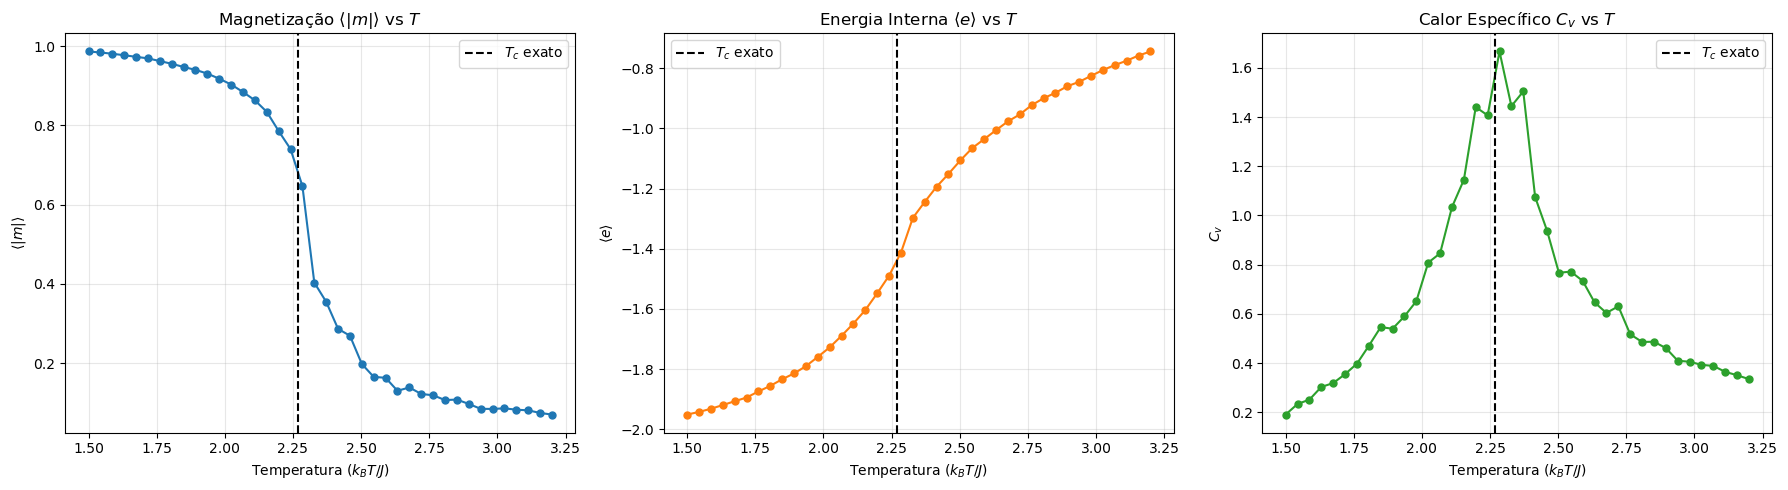

In [7]:
# CÉLULA: Termodinâmica (M, E, Cv)
fig, axs = plt.subplots(1, 3, figsize=(18, 5))
L_plot = 32 # Escolhendo a maior rede simulada anteriormente para mostrar
res = resultados[L_plot]

# 1. Magnetização vs T
axs[0].plot(temperaturas, res['M'], 'o-', color='#1f77b4', markersize=5)
axs[0].set_title(r'Magnetização $\langle |m| \rangle$ vs $T$')
axs[0].set_ylabel(r'$\langle |m| \rangle$')

# 2. Energia Interna vs T
axs[1].plot(temperaturas, res['E'], 'o-', color='#ff7f0e', markersize=5)
axs[1].set_title(r'Energia Interna $\langle e \rangle$ vs $T$')
axs[1].set_ylabel(r'$\langle e \rangle$')

# 3. Calor Específico vs T
axs[2].plot(temperaturas, res['Cv'], 'o-', color='#2ca02c', markersize=5)
axs[2].set_title(r'Calor Específico $C_v$ vs $T$')
axs[2].set_ylabel(r'$C_v$')

for ax in axs:
    ax.set_xlabel(r'Temperatura ($k_B T / J$)')
    ax.axvline(x=Tc_exact, color='k', linestyle='--', label=r'$T_c$ exato')
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

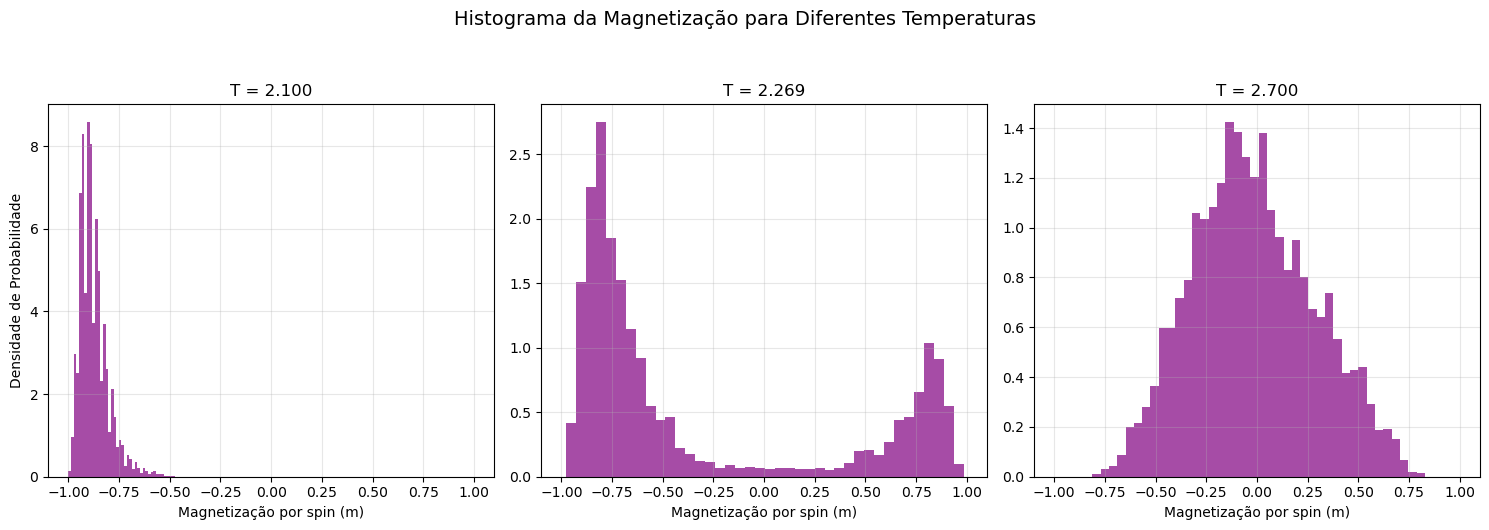

In [8]:
# CÉLULA: Histograma da Magnetização
L_hist = 16 # Rede menor facilita a transição entre estados (flip global) para ver a bimodalidade
passos_amostragem = 10000
T_hists = [2.1, Tc_exact, 2.7]

fig, axs = plt.subplots(1, 3, figsize=(15, 5))

for i, T in enumerate(T_hists):
    beta = 1.0 / T
    rede = inicializar_rede(L_hist)
    magnetizacoes = np.zeros(passos_amostragem)
    
    # Termalização
    for _ in range(1000):
        passo_metropolis(rede, beta)
        
    # Amostragem (série temporal da magnetização com sinal)
    for step in range(passos_amostragem):
        passo_metropolis(rede, beta)
        _, M = calcular_energia_magnetizacao(rede)
        magnetizacoes[step] = M / (L_hist**2)
        
    axs[i].hist(magnetizacoes, bins=40, color='purple', alpha=0.7, density=True)
    axs[i].set_title(f'T = {T:.3f}')
    axs[i].set_xlabel('Magnetização por spin (m)')
    axs[i].set_xlim(-1.1, 1.1)
    axs[i].grid(True, alpha=0.3)

axs[0].set_ylabel('Densidade de Probabilidade')
plt.suptitle('Histograma da Magnetização para Diferentes Temperaturas', fontsize=14, y=1.05)
plt.tight_layout()
plt.show()

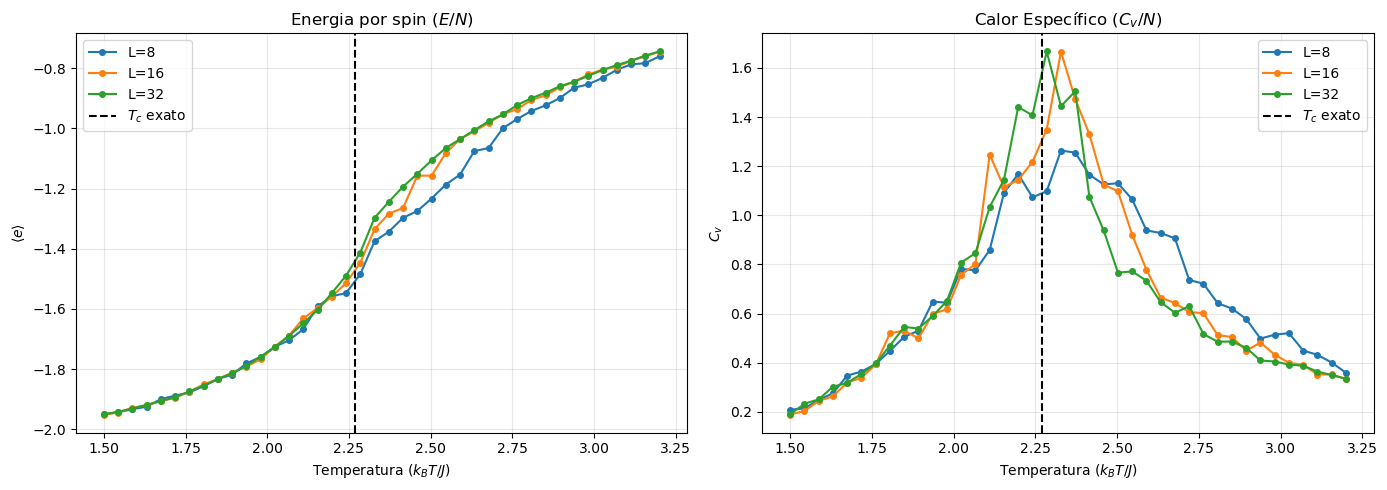

In [10]:
# ==========================================
# FIGURA 1: Energia e Calor Específico vs T
# ==========================================
fig1, axs1 = plt.subplots(1, 2, figsize=(14, 5))
cores = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']

for idx, L in enumerate(tamanhos_L):
    res = resultados[L]
    axs1[0].plot(temperaturas, res['E'], 'o-', color=cores[idx], label=f'L={L}', markersize=4)
    axs1[1].plot(temperaturas, res['Cv'], 'o-', color=cores[idx], label=f'L={L}', markersize=4)

axs1[0].set_title(r'Energia por spin ($E/N$)')
axs1[0].set_ylabel(r'$\langle e \rangle$')
axs1[1].set_title(r'Calor Específico ($C_v/N$)')
axs1[1].set_ylabel(r'$C_v$')

for ax in axs1:
    ax.set_xlabel(r'Temperatura ($k_B T / J$)')
    ax.axvline(x=Tc_exact, color='k', linestyle='--', label=r'$T_c$ exato')
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

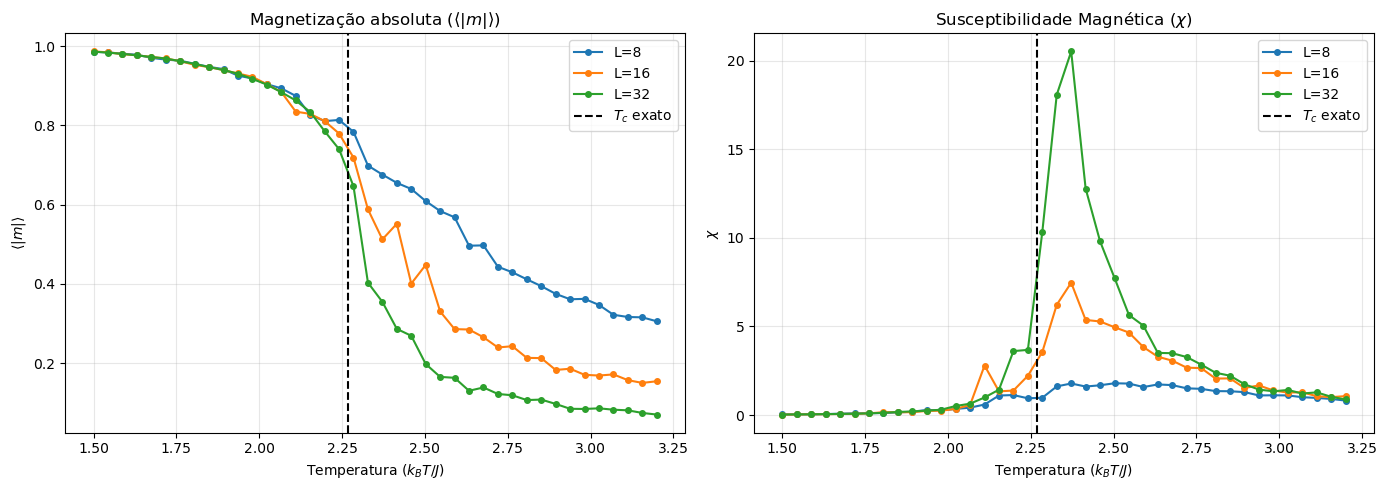

In [11]:
# ==========================================
# FIGURA 2: Magnetização e Susceptibilidade
# ==========================================
fig2, axs2 = plt.subplots(1, 2, figsize=(14, 5))

for idx, L in enumerate(tamanhos_L):
    res = resultados[L]
    axs2[0].plot(temperaturas, res['M'], 'o-', color=cores[idx], label=f'L={L}', markersize=4)
    axs2[1].plot(temperaturas, res['Chi'], 'o-', color=cores[idx], label=f'L={L}', markersize=4)

axs2[0].set_title(r'Magnetização absoluta ($\langle |m| \rangle$)')
axs2[0].set_ylabel(r'$\langle |m| \rangle$')
axs2[1].set_title(r'Susceptibilidade Magnética ($\chi$)')
axs2[1].set_ylabel(r'$\chi$')

for ax in axs2:
    ax.set_xlabel(r'Temperatura ($k_B T / J$)')
    ax.axvline(x=Tc_exact, color='k', linestyle='--', label=r'$T_c$ exato')
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

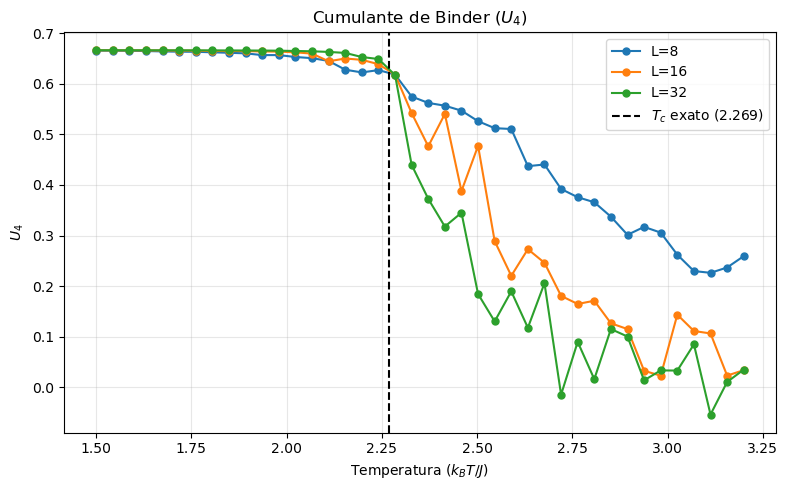

In [12]:
# ==========================================
# FIGURA 4: Cumulante de Binder (U_4)
# ==========================================
fig4, ax4 = plt.subplots(figsize=(8, 5))

for idx, L in enumerate(tamanhos_L):
    ax4.plot(temperaturas, resultados[L]['U4'], 'o-', color=cores[idx], label=f'L={L}', markersize=5)

ax4.set_title(r'Cumulante de Binder ($U_4$)')
ax4.set_xlabel(r'Temperatura ($k_B T / J$)')
ax4.set_ylabel(r'$U_4$')
ax4.axvline(x=Tc_exact, color='k', linestyle='--', label=r'$T_c$ exato (2.269)')
ax4.grid(True, alpha=0.3)
ax4.legend()

plt.tight_layout()
plt.show()

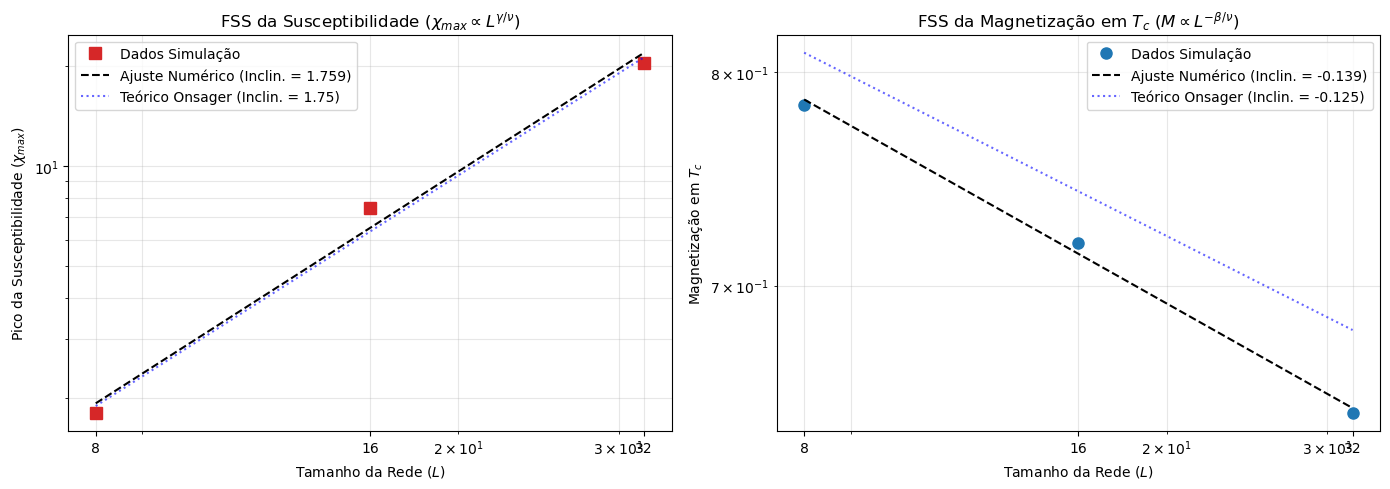

=== RESULTADOS DO FINITE-SIZE SCALING ===
Razão γ/ν (Teórica): 1.750 | Obtida: 1.759
Razão β/ν (Teórica): 0.125 | Obtida: 0.139


In [14]:
# ==========================================
# FIGURA 3: Finite-Size Scaling (Expoentes Críticos)
# ==========================================
L_vals = np.array(tamanhos_L)
chi_max = np.zeros(len(L_vals))
m_tc = np.zeros(len(L_vals))

# Encontra o índice da temperatura simulada mais próxima do Tc exato
idx_tc = np.argmin(np.abs(temperaturas - Tc_exact))

for i, L in enumerate(L_vals):
    chi_max[i] = np.max(resultados[L]['Chi'])  # Pico da susceptibilidade
    m_tc[i] = resultados[L]['M'][idx_tc]       # Magnetização em Tc

# Regressão linear em escala log-log (ln(y) = inclinação * ln(x) + intercepto)
log_L = np.log(L_vals)

# Ajuste para Susceptibilidade (gamma/nu)
coef_chi = np.polyfit(log_L, np.log(chi_max), 1)
gamma_nu_medido = coef_chi[0]

# Ajuste para Magnetização (-beta/nu)
coef_m = np.polyfit(log_L, np.log(m_tc), 1)
beta_nu_medido = -coef_m[0]

# Valores Teóricos de Onsager
gamma_nu_teo = 1.75   # gamma=7/4, nu=1
beta_nu_teo = 0.125   # beta=1/8, nu=1

# Configuração dos plots
fig3, axs3 = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Susceptibilidade vs L
axs3[0].loglog(L_vals, chi_max, 's', color='#d62728', markersize=8, label='Dados Simulação')
axs3[0].plot(L_vals, np.exp(coef_chi[1]) * L_vals**coef_chi[0], 'k--', 
             label=f'Ajuste Numérico (Inclin. = {gamma_nu_medido:.3f})')
axs3[0].plot(L_vals, np.exp(coef_chi[1]) * L_vals**gamma_nu_teo, 'b:', alpha=0.6,
             label=f'Teórico Onsager (Inclin. = {gamma_nu_teo})')
axs3[0].set_title(r'FSS da Susceptibilidade ($\chi_{max} \propto L^{\gamma/\nu}$)')
axs3[0].set_xlabel(r'Tamanho da Rede ($L$)')
axs3[0].set_ylabel(r'Pico da Susceptibilidade ($\chi_{max}$)')

# Plot 2: Magnetização vs L
axs3[1].loglog(L_vals, m_tc, 'o', color='#1f77b4', markersize=8, label='Dados Simulação')
axs3[1].plot(L_vals, np.exp(coef_m[1]) * L_vals**coef_m[0], 'k--', 
             label=f'Ajuste Numérico (Inclin. = {-beta_nu_medido:.3f})')
axs3[1].plot(L_vals, np.exp(coef_m[1]) * L_vals**(-beta_nu_teo), 'b:', alpha=0.6,
             label=f'Teórico Onsager (Inclin. = {-beta_nu_teo})')
axs3[1].set_title(r'FSS da Magnetização em $T_c$ ($M \propto L^{-\beta/\nu}$)')
axs3[1].set_xlabel(r'Tamanho da Rede ($L$)')
axs3[1].set_ylabel(r'Magnetização em $T_c$')

for ax in axs3:
    # Formata ticks para aparecerem os valores corretos de L
    ax.set_xticks(L_vals)
    ax.set_xticklabels(L_vals)
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

# Imprime o sumário numérico para o artigo
print("=== RESULTADOS DO FINITE-SIZE SCALING ===")
print(f"Razão γ/ν (Teórica): {gamma_nu_teo:.3f} | Obtida: {gamma_nu_medido:.3f}")
print(f"Razão β/ν (Teórica): {beta_nu_teo:.3f} | Obtida: {beta_nu_medido:.3f}")